# E-Commerce Sales Data Analysis & Exploratory Data Analysis (EDA)

## Overview

In this notebook, we perform Exploratory Data Analysis (EDA) on an e-commerce sales dataset.

The goal of this project is to understand the data structure, identify data quality issues, analyze customer behavior, evaluate product performance, and discover sales patterns.

The dataset contains:
- Customer information
- Product details
- Order transactions
- Payment records

The analysis is performed using Python libraries such as Pandas, Matplotlib, and Seaborn.

## 1. Import Required Libraries

In this section, we import the necessary Python libraries for data manipulation, visualization, and statistical analysis.

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

## 2. Load Dataset

The cleaned dataset is loaded into a Pandas DataFrame.

This dataset was prepared through an ETL process including data cleaning, transformation, and integration.

In [4]:
df=pd.read_csv("sales.csv")
df

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue
0,500001,103695,2025-08-28,2003,4.0,10.0,Gateway,Completed,36.0,Qom,2024-03-05,Regular,USB-C Cable,Accessories,9.0,32.0,32.0
1,500002,107935,2024-05-31,2014,1.0,10.0,Wallet,Completed,49.0,Kerman,2025-06-04,Regular,Backpack,Accessories,42.0,38.0,38.0
2,500003,105141,2025-08-10,2002,1.0,20.0,CardToCard,Completed,36.0,Tehran,2025-10-19,Regular,Mechanical Keyboard,Electronics,62.0,50.0,50.0
3,500004,108780,2024-10-11,2012,1.0,10.0,Gateway,Completed,45.0,Shiraz,2023-12-07,Regular,Office Chair,Home Office,180.0,162.0,162.0
4,500005,101187,2024-02-19,2008,2.0,0.0,Gateway,Completed,24.0,Karaj,2023-12-02,Regular,Phone Case,Accessories,14.0,28.0,28.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49217,549996,104649,2025-04-30,2013,2.0,5.0,CardToCard,Completed,32.0,Tehran,2025-03-24,Regular,Notebook,Stationery,7.0,13.0,13.0
49218,549997,108686,2025-01-26,2004,1.0,10.0,Gateway,Completed,45.0,Tehran,2024-03-08,New,Power Bank,Electronics,35.0,32.0,32.0
49219,549998,107639,2026-04-13,2010,1.0,0.0,Cash,Completed,56.0,Shiraz,2025-02-19,Regular,Fitness Band,Wearables,55.0,55.0,55.0
49220,549999,108215,2025-04-18,2005,1.0,0.0,CardToCard,Completed,20.0,Qom,2025-08-11,Regular,Laptop Stand,Accessories,28.0,28.0,28.0


In [3]:
df = pd.read_csv("sales.csv")

df.head()

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue
0,500001,103695,2025-08-28,2003,4.0,10.0,Gateway,Completed,36.0,Qom,2024-03-05,Regular,USB-C Cable,Accessories,9.0,32.0,32.0
1,500002,107935,2024-05-31,2014,1.0,10.0,Wallet,Completed,49.0,Kerman,2025-06-04,Regular,Backpack,Accessories,42.0,38.0,38.0
2,500003,105141,2025-08-10,2002,1.0,20.0,CardToCard,Completed,36.0,Tehran,2025-10-19,Regular,Mechanical Keyboard,Electronics,62.0,50.0,50.0
3,500004,108780,2024-10-11,2012,1.0,10.0,Gateway,Completed,45.0,Shiraz,2023-12-07,Regular,Office Chair,Home Office,180.0,162.0,162.0
4,500005,101187,2024-02-19,2008,2.0,0.0,Gateway,Completed,24.0,Karaj,2023-12-02,Regular,Phone Case,Accessories,14.0,28.0,28.0


## 3. Dataset Overview

Before starting the analysis, we inspect the dataset structure.

We check:
- Dataset dimensions
- Column names
- Data types
- Sample records

In [3]:
# Number of rows and columns

df.shape

(49222, 17)

In [4]:
# Column names

df.columns

Index(['OrderID', 'CustomerID', 'OrderDate', 'ProductID', 'Quantity',
       'Discount', 'PaymentMethod', 'Status', 'Age', 'City', 'SignupDate',
       'CustomerSegment', 'ProductName', 'Category', 'UnitPrice', 'Sales',
       'OrderValue'],
      dtype='object')

In [5]:
# Dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49222 entries, 0 to 49221
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          49222 non-null  int64  
 1   CustomerID       49222 non-null  int64  
 2   OrderDate        49222 non-null  object 
 3   ProductID        49222 non-null  int64  
 4   Quantity         49222 non-null  float64
 5   Discount         49222 non-null  float64
 6   PaymentMethod    49222 non-null  object 
 7   Status           49222 non-null  object 
 8   Age              49222 non-null  float64
 9   City             49222 non-null  object 
 10  SignupDate       49222 non-null  object 
 11  CustomerSegment  49222 non-null  object 
 12  ProductName      49222 non-null  object 
 13  Category         49222 non-null  object 
 14  UnitPrice        49222 non-null  float64
 15  Sales            49222 non-null  float64
 16  OrderValue       49222 non-null  float64
dtypes: float64(6

In [6]:
# First rows

df.head()

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue
0,500001,103695,2025-08-28,2003,4.0,10.0,Gateway,Completed,36.0,Qom,2024-03-05,Regular,USB-C Cable,Accessories,9.0,32.0,32.0
1,500002,107935,2024-05-31,2014,1.0,10.0,Wallet,Completed,49.0,Kerman,2025-06-04,Regular,Backpack,Accessories,42.0,38.0,38.0
2,500003,105141,2025-08-10,2002,1.0,20.0,CardToCard,Completed,36.0,Tehran,2025-10-19,Regular,Mechanical Keyboard,Electronics,62.0,50.0,50.0
3,500004,108780,2024-10-11,2012,1.0,10.0,Gateway,Completed,45.0,Shiraz,2023-12-07,Regular,Office Chair,Home Office,180.0,162.0,162.0
4,500005,101187,2024-02-19,2008,2.0,0.0,Gateway,Completed,24.0,Karaj,2023-12-02,Regular,Phone Case,Accessories,14.0,28.0,28.0


## 4. Data Quality Assessment

Data quality is an important step before performing analysis.

In this section, we check:
- Missing values
- Duplicate records
- Unique values

This ensures that the analysis is based on reliable data.

In [7]:
df.isnull().sum()

OrderID            0
CustomerID         0
OrderDate          0
ProductID          0
Quantity           0
Discount           0
PaymentMethod      0
Status             0
Age                0
City               0
SignupDate         0
CustomerSegment    0
ProductName        0
Category           0
UnitPrice          0
Sales              0
OrderValue         0
dtype: int64

In [8]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).sort_values(ascending=False)

missing_percentage

OrderID            0.0
CustomerID         0.0
OrderDate          0.0
ProductID          0.0
Quantity           0.0
Discount           0.0
PaymentMethod      0.0
Status             0.0
Age                0.0
City               0.0
SignupDate         0.0
CustomerSegment    0.0
ProductName        0.0
Category           0.0
UnitPrice          0.0
Sales              0.0
OrderValue         0.0
dtype: float64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df[df.duplicated(keep=False)].head()

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue


In [11]:
df.nunique()

OrderID            49222
CustomerID          9820
OrderDate            912
ProductID             20
Quantity               8
Discount               6
PaymentMethod          4
Status                 3
Age                   48
City                  10
SignupDate          1094
CustomerSegment        3
ProductName           20
Category               6
UnitPrice             20
Sales                290
OrderValue           290
dtype: int64

## 5. Descriptive Statistics

Statistical analysis helps us understand numerical features.

We analyze:
- Mean
- Median
- Minimum and maximum values
- Data distribution

In [12]:
df.describe()

,OrderID,CustomerID,ProductID,Quantity,Discount,Age,UnitPrice,Sales,OrderValue
count,49222.000000,49222.000000,49222.000000,49222.000000,49222.000000,49222.000000,49222.000000,49222.000000,49222.000000
mean,525007.608366,105002.304356,2009.460160,1.881923,7.485576,41.283369,40.286579,69.985576,69.985576
std,14435.345449,2888.912895,5.578603,1.079382,7.754378,13.681355,42.613062,94.483273,94.483273
min,500001.000000,100001.000000,2001.000000,-2.000000,0.000000,18.000000,7.000000,-170.000000,-170.000000
25%,512507.250000,102504.000000,2004.000000,1.000000,0.000000,29.000000,11.000000,17.000000,17.000000
50%,525016.500000,105005.000000,2008.000000,2.000000,5.000000,41.000000,28.000000,38.000000,38.000000
75%,537506.750000,107497.000000,2014.000000,2.000000,10.000000,53.000000,58.000000,84.000000,84.000000
max,550000.000000,110000.000000,2020.000000,5.000000,30.000000,65.000000,260.000000,1300.000000,1300.000000


In [13]:
df.describe(include="all")

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,Age,City,SignupDate,CustomerSegment,ProductName,Category,UnitPrice,Sales,OrderValue
count,49222.000000,49222.000000,49222,49222.000000,49222.000000,49222.000000,49222,49222,49222.000000,49222,49222,49222,49222,49222,49222.000000,49222.000000,49222.000000
unique,NaN,NaN,912,NaN,NaN,NaN,4,3,NaN,10,1094,3,20,6,NaN,NaN,NaN
top,NaN,NaN,2025-09-05,NaN,NaN,NaN,Gateway,Completed,NaN,Tehran,2023-03-07,Regular,Notebook,Accessories,NaN,NaN,NaN
freq,NaN,NaN,86,NaN,NaN,NaN,23894,45276,NaN,14001,105,27296,5440,18189,NaN,NaN,NaN
mean,525007.608366,105002.304356,NaN,2009.460160,1.881923,7.485576,NaN,NaN,41.283369,NaN,NaN,NaN,NaN,NaN,40.286579,69.985576,69.985576
std,14435.345449,2888.912895,NaN,5.578603,1.079382,7.754378,NaN,NaN,13.681355,NaN,NaN,NaN,NaN,NaN,42.613062,94.483273,94.483273
min,500001.000000,100001.000000,NaN,2001.000000,-2.000000,0.000000,NaN,NaN,18.000000,NaN,NaN,NaN,NaN,NaN,7.000000,-170.000000,-170.000000
25%,512507.250000,102504.000000,NaN,2004.000000,1.000000,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,11.000000,17.000000,17.000000
50%,525016.500000,105005.000000,NaN,2008.000000,2.000000,5.000000,NaN,NaN,41.000000,NaN,NaN,NaN,NaN,NaN,28.000000,38.000000,38.000000
75%,537506.750000,107497.000000,NaN,2014.000000,2.000000,10.000000,NaN,NaN,53.000000,NaN,NaN,NaN,NaN,NaN,58.000000,84.000000,84.000000


## 6. Customer Analysis

This section focuses on understanding customer behavior.

We analyze:
- Customer distribution by city
- Customer segments
- Age distribution

In [14]:
df["City"].value_counts()

City
Tehran     14001
Mashhad     6222
Karaj       4966
Isfahan     4916
Shiraz      4363
Tabriz      4134
Ahvaz       2923
Rasht       2857
Kerman      2465
Qom         2375
Name: count, dtype: int64

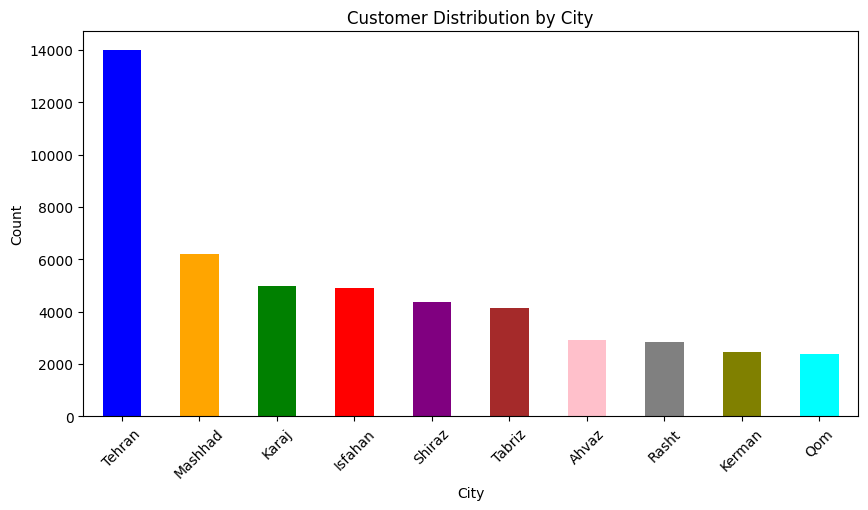

In [5]:
plt.figure(figsize=(10,5))

df["City"].value_counts().plot(
    kind="bar",
    color=[
        "blue",
        "orange",
        "green",
        "red",
        "purple",
        "brown",
        "pink",
        "gray",
        "olive",
        "cyan"
    ]
)

plt.title("Customer Distribution by City")
plt.xlabel("City")
plt.ylabel("Count")

plt.xticks(rotation=45)

plt.show()

In [16]:
df["CustomerSegment"].value_counts()

CustomerSegment
Regular    27296
New        17056
VIP         4870
Name: count, dtype: int64

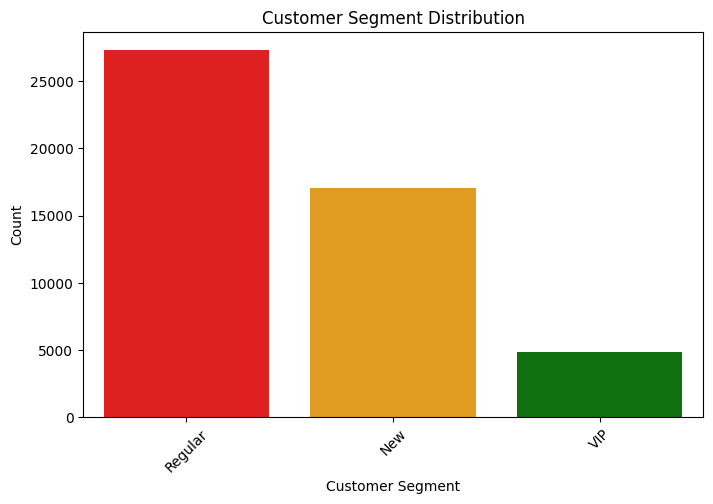

In [7]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="CustomerSegment",
    palette=["Red", "orange", "green"]
)

plt.title("Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Count")

plt.xticks(rotation=45)

plt.show()

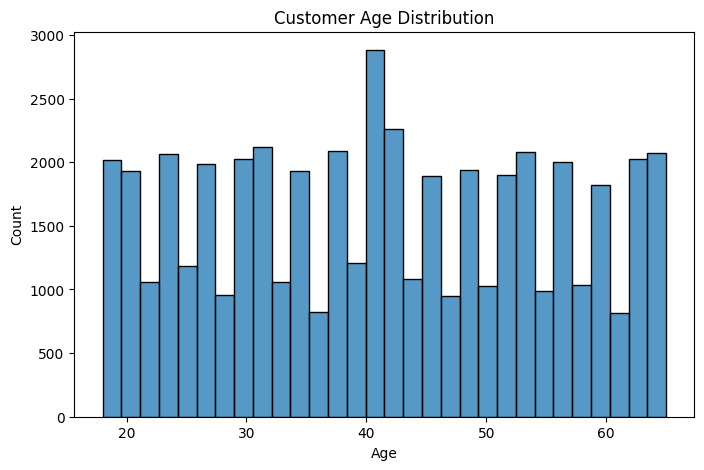

In [18]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=df,
    x="Age",
    bins=30
)

plt.title("Customer Age Distribution")

plt.show()

## 7. Product Performance Analysis

This section analyzes product performance.

We explore:
- Product categories
- Best-selling products
- Revenue contribution

In [19]:
df["Category"].value_counts()

Category
Accessories    18189
Electronics    17765
Stationery      5440
Home Office     3122
Wearables       3043
Gaming          1663
Name: count, dtype: int64

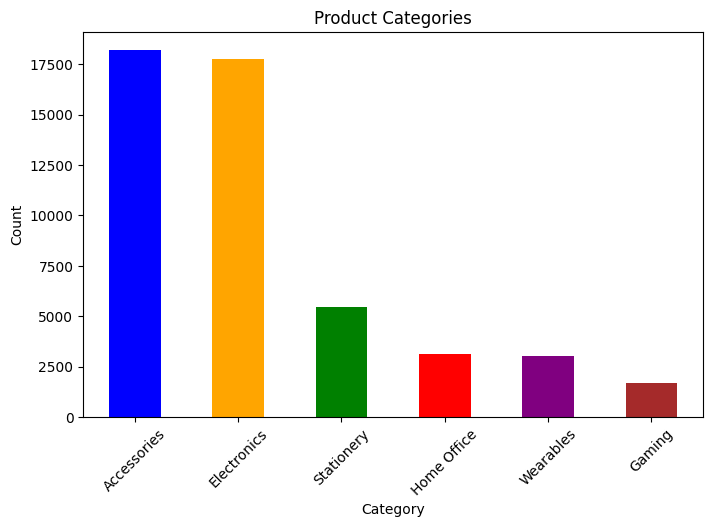

In [8]:
plt.figure(figsize=(8,5))

df["Category"].value_counts().plot(
    kind="bar",
    color=[
        "blue",
        "orange",
        "green",
        "red",
        "purple",
        "brown"
    ]
)

plt.title("Product Categories")
plt.xlabel("Category")
plt.ylabel("Count")

plt.xticks(rotation=45)

plt.show()

In [14]:
top_products = (
    df.groupby("ProductName")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

ProductName
Headphones             333411.0
Office Chair           329292.0
Tablet                 292344.0
Smart Watch            259590.0
Microphone             230139.0
Mechanical Keyboard    229676.0
Bluetooth Speaker      213311.0
Gaming Controller      198037.0
Power Bank             180004.0
Fitness Band           169860.0
Name: Sales, dtype: float64

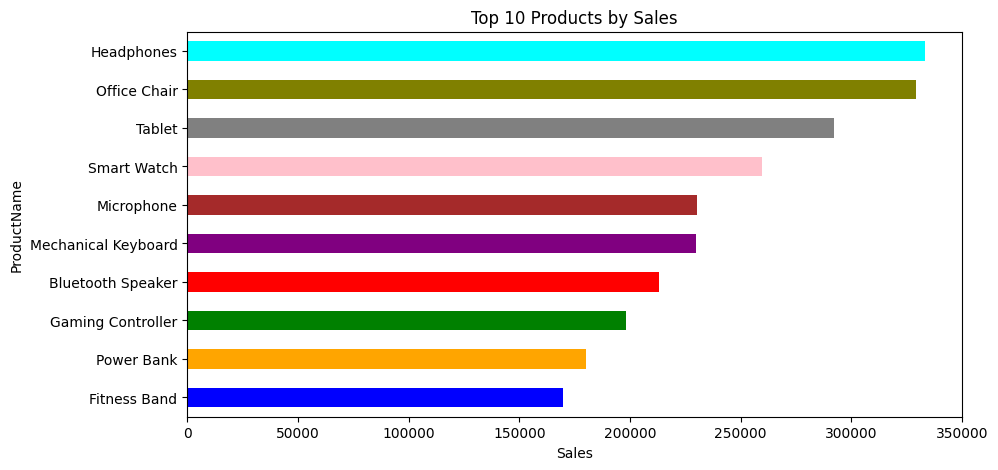

In [16]:
plt.figure(figsize=(10,5))

top_products.sort_values().plot(
    kind="barh",
    color=[
        "blue",
        "orange",
        "green",
        "red",
        "purple",
        "brown",
        "pink",
        "gray",
        "olive",
        "cyan"
    ]
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Sales")
plt.ylabel("ProductName")

plt.show()

## 8. Sales Analysis

Sales analysis helps understand business performance.

We analyze:
- Total sales
- Sales by category
- Sales trends

In [23]:
total_sales = df["Sales"].sum()

total_sales

np.float64(3444830.0)

In [18]:
category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

category_sales

Category
Electronics    1751037.0
Accessories     553023.0
Home Office     446065.0
Wearables       429450.0
Gaming          198037.0
Stationery       67218.0
Name: Sales, dtype: float64

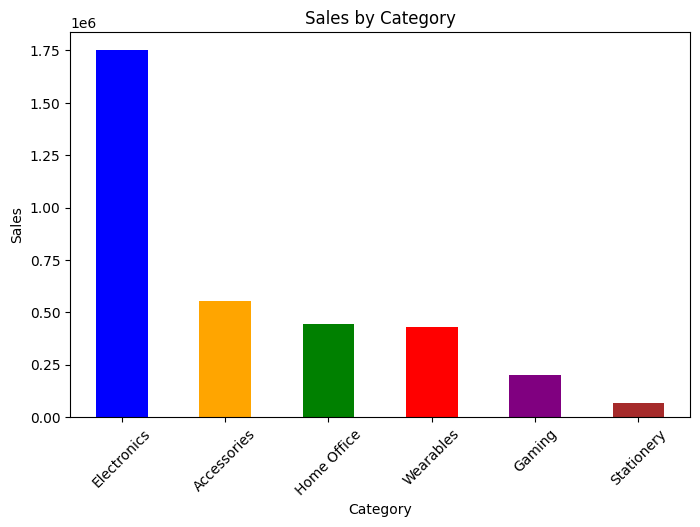

In [19]:
plt.figure(figsize=(8,5))

category_sales.plot(
    kind="bar",
    color=[
        "blue",
        "orange",
        "green",
        "red",
        "purple",
        "brown"
    ]
)

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")

plt.xticks(rotation=45)

plt.show()

## 9. Time-Based Analysis

We analyze sales trends over time to identify patterns and changes.

In [26]:
df["OrderDate"] = pd.to_datetime(df["OrderDate"])

In [27]:
monthly_sales = (
    df.groupby(
        df["OrderDate"].dt.to_period("M")
    )["Sales"]
    .sum()
)

monthly_sales

OrderDate
2024-01    121893.0
2024-02    114664.0
2024-03    128150.0
2024-04    115941.0
2024-05    123683.0
2024-06    116784.0
2024-07    128689.0
2024-08    129987.0
2024-09    115943.0
2024-10    117260.0
2024-11    121208.0
2024-12    125897.0
2025-01    118487.0
2025-02    108609.0
2025-03    119432.0
2025-04    115278.0
2025-05    130607.0
2025-06    126269.0
2025-07    119743.0
2025-08    120441.0
2025-09    119935.0
2025-10    124299.0
2025-11    125300.0
2025-12    115790.0
2026-01    130550.0
2026-02     75132.0
2026-03     84082.0
2026-04     85706.0
2026-05     85986.0
2026-06     79085.0
Freq: M, Name: Sales, dtype: float64

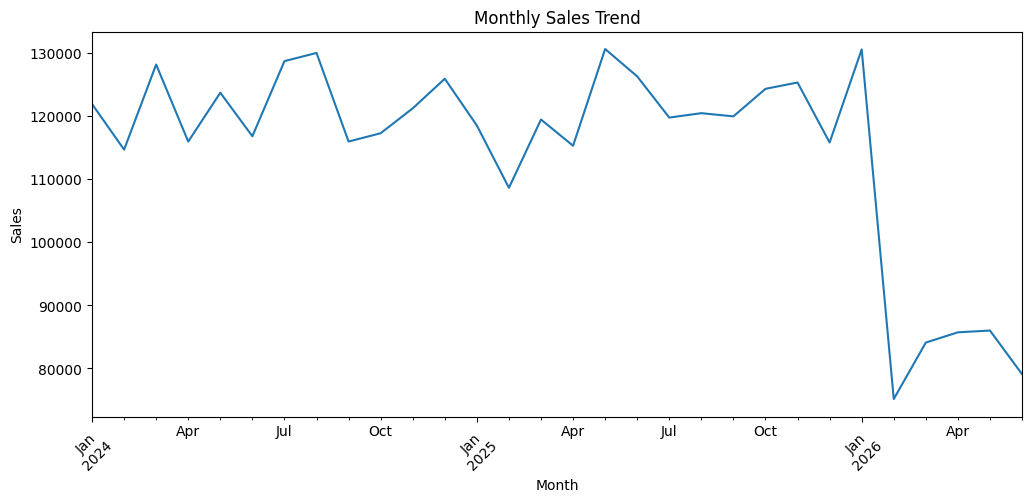

In [28]:
plt.figure(figsize=(12,5))

monthly_sales.plot()

plt.title("Monthly Sales Trend")

plt.xlabel("Month")

plt.ylabel("Sales")

plt.xticks(rotation=45)

plt.show()

## 10. Correlation Analysis

Correlation analysis helps us understand relationships between numerical variables.

In [29]:
numeric_df = df.select_dtypes(
    include="number"
)

corr = numeric_df.corr()

corr

,OrderID,CustomerID,ProductID,Quantity,Discount,Age,UnitPrice,Sales,OrderValue
OrderID,1.000000,0.002114,0.004012,-0.009637,-0.004664,-0.001657,-0.002537,-0.003431,-0.003431
CustomerID,0.002114,1.000000,-0.003458,0.001314,-0.001541,-0.006141,0.002855,0.005235,0.005235
ProductID,0.004012,-0.003458,1.000000,-0.003227,0.001731,0.003710,0.231946,0.181525,0.181525
Quantity,-0.009637,0.001314,-0.003227,1.000000,0.001848,-0.002204,-0.002164,0.420637,0.420637
Discount,-0.004664,-0.001541,0.001731,0.001848,1.000000,0.003098,0.006917,-0.053738,-0.053738
Age,-0.001657,-0.006141,0.003710,-0.002204,0.003098,1.000000,0.002204,-0.001692,-0.001692
UnitPrice,-0.002537,0.002855,0.231946,-0.002164,0.006917,0.002204,1.000000,0.782302,0.782302
Sales,-0.003431,0.005235,0.181525,0.420637,-0.053738,-0.001692,0.782302,1.000000,1.000000
OrderValue,-0.003431,0.005235,0.181525,0.420637,-0.053738,-0.001692,0.782302,1.000000,1.000000


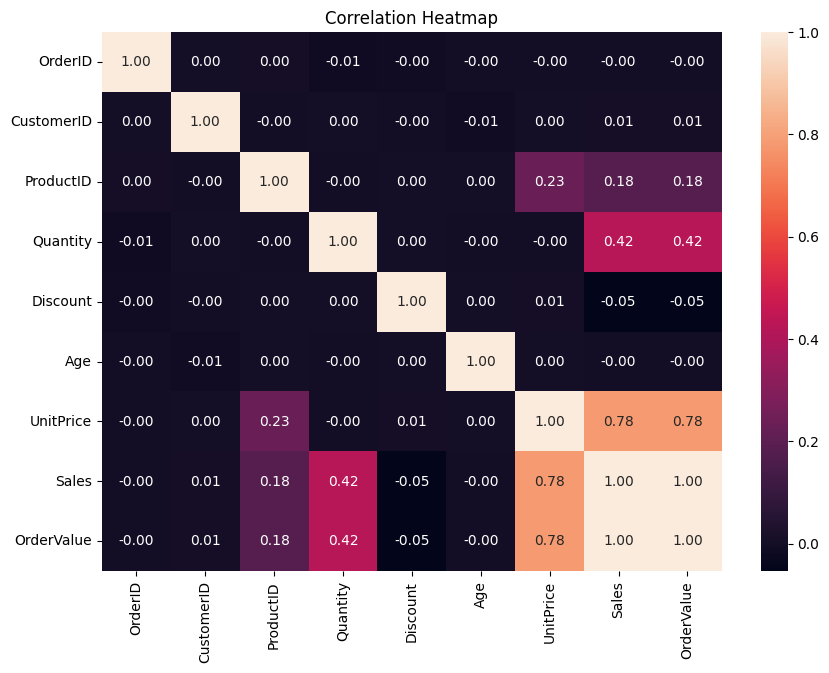

In [30]:
plt.figure(figsize=(10,7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

# Conclusion

In this project, exploratory data analysis was performed on e-commerce sales data.

The analysis included:
- Data quality checking
- Customer behavior analysis
- Product performance analysis
- Sales trend analysis
- Data visualization

The results provide useful insights for understanding business performance and supporting decision-making.